In [1]:
# Ridership in this project we will predict that how much people will go by bus or rail like for next day.

In [2]:
import torch
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
import torchmetrics as tm
from pathlib import Path

In [3]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

In [4]:
# Get the dataset
dataset_path = Path('../datasets/cta.csv')
ridership = pd.read_csv(dataset_path, parse_dates=['service_date'])
ridership.columns = ['date', 'type', 'bus', 'rail', 'total']
ridership = ridership.sort_values('date').set_index('date')
ridership = ridership.drop('total', axis=1)
ridership = ridership.drop_duplicates()


In [5]:
ridership.head()

,type,bus,rail
date,,,
2001-01-01,U,"297,192","126,455"
2001-01-02,W,"780,827","501,952"
2001-01-03,W,"824,923","536,432"
2001-01-04,W,"870,021","550,011"
2001-01-05,W,"890,426","557,917"


In [6]:
ridership.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8947 entries, 2001-01-01 to 2025-06-30
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   type    8947 non-null   str  
 1   bus     8947 non-null   str  
 2   rail    8947 non-null   str  
dtypes: str(3)
memory usage: 279.6 KB


In [7]:
# All the values of bus and rail are string we need covert this into integer
ridership['bus'] = ridership['bus'].values.map(lambda val: int(val.replace(',', '')))
ridership['rail'] = ridership['rail'].values.map(lambda val: int(val.replace(',', '')))

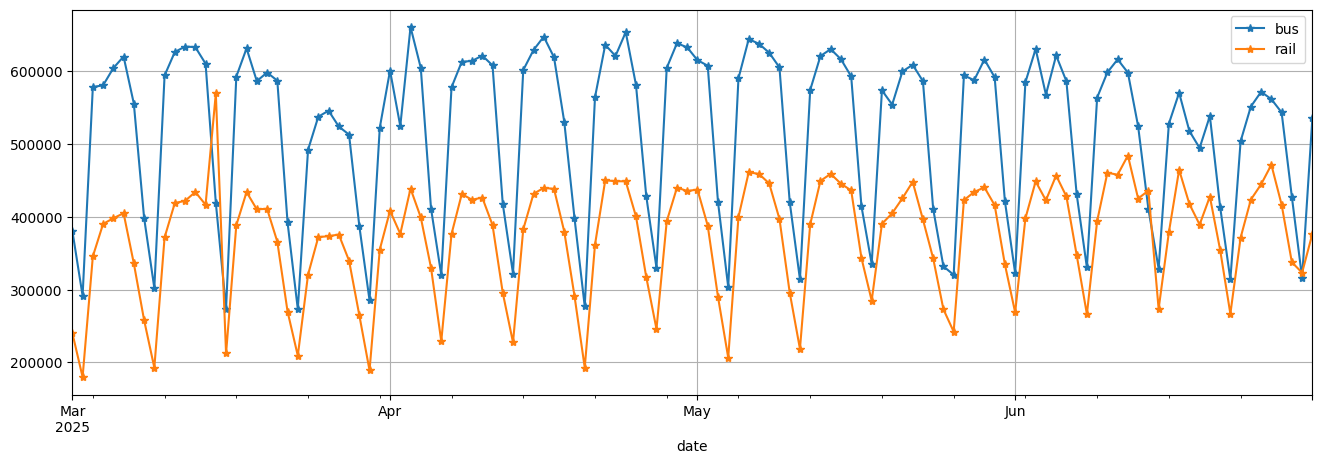

In [8]:
# visualize the data
ridership['2025-03': '2025-06'].plot(grid=True, marker="*", figsize=(16, 5))
plt.show()

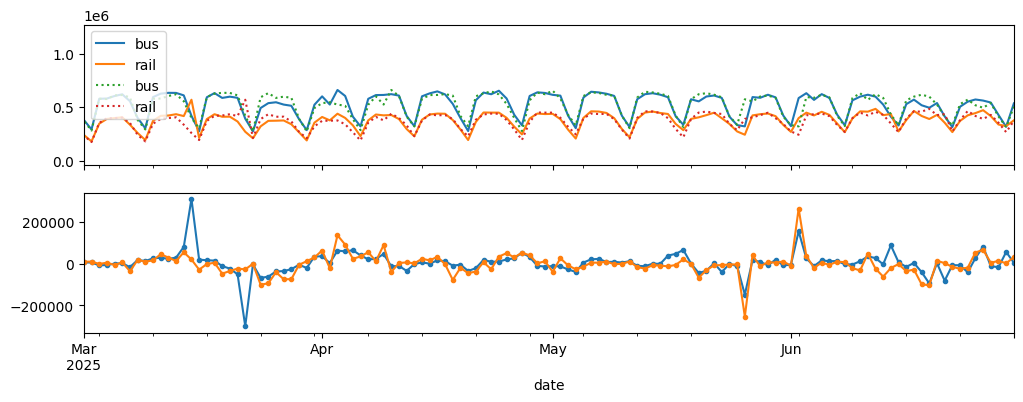

In [9]:
# shift it by 7 days
ridership_diff_7 = ridership[['rail', 'bus']].diff(7)['2025-03': '2025-06']
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(12, 4))
ridership.plot(ax=ax[0], )
ridership.shift(7).plot(ax=ax[0], linestyle=':')

ridership_diff_7.plot(ax=ax[1], legend=False, marker='.')
plt.show()

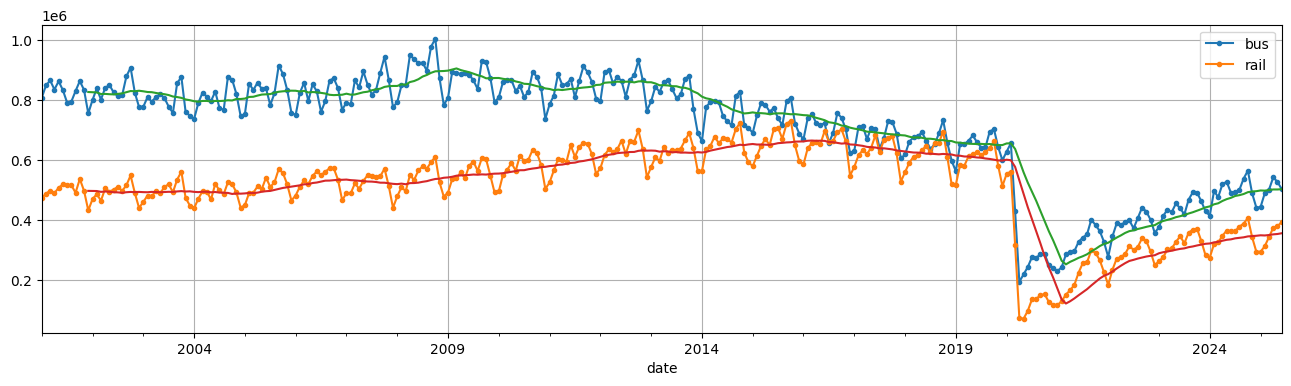

In [10]:
period = slice('2001', '2025')
ridership_monthly = ridership.select_dtypes(include='number').resample('ME').mean()
rolling_average_12_months = ridership_monthly.loc[period].rolling(12).mean()
fig, ax = plt.subplots(figsize=(16, 4))
ridership_monthly[period].plot(ax=ax, marker='.')
rolling_average_12_months.plot(ax=ax, grid=True, legend=False)
plt.show()


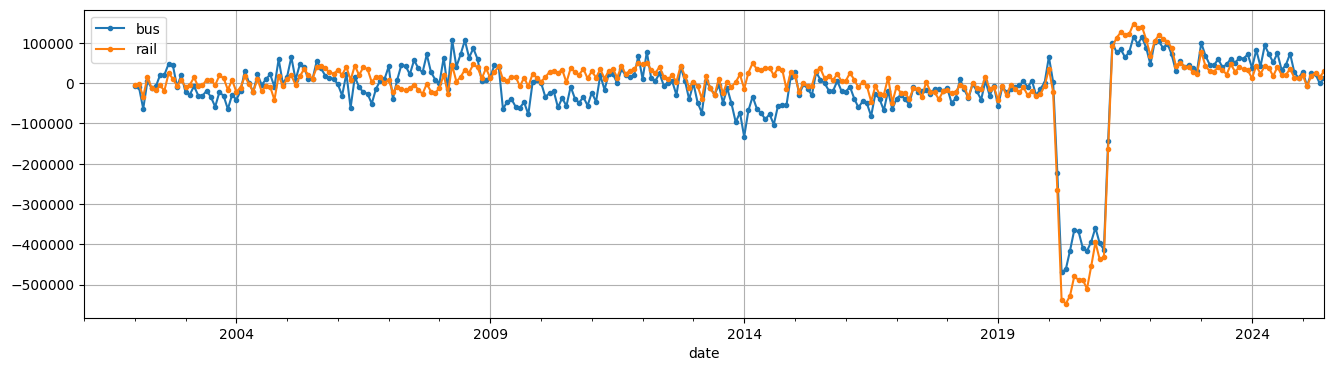

In [11]:
ridership_monthly.diff(12)[period].plot(grid=True, marker='.', figsize=(16,4))
plt.show()

In [12]:
# Prepare the data for ml model

In [13]:
class MultitaskTimeSeriesDataset(torch.utils.data.Dataset):
    def __init__(self, series, window_length):
        super().__init__()
        self.series = series
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, idx):
        if idx >= len(self):
            raise IndexError("Dataset is out of range")

        end = idx + self.window_length
        window = self.series[idx : end]
        target = self.series[end]

        return window, target[:2]
        

In [63]:
# example
my_series = torch.tensor([[0], [1], [2], [3], [4], [5]])
my_dataset = MultitaskTimeSeriesDataset(my_series, window_length=2)
for window, target in my_dataset:
    print("Window:", window, " Target:", target)
my_series.shape

Window: tensor([[0],
        [1]])  Target: tensor([2])
Window: tensor([[1],
        [2]])  Target: tensor([3])
Window: tensor([[2],
        [3]])  Target: tensor([4])
Window: tensor([[3],
        [4]])  Target: tensor([5])


torch.Size([6, 1])

In [15]:
# example dataset convert dataset into dataloader

from torch.utils.data import DataLoader
torch.manual_seed(0)

my_loader = DataLoader(my_dataset, batch_size=2, shuffle=True)
for X, y in my_loader:
    print(f"X: {X}, y: {y}")

X: tensor([[[2],
         [3]],

        [[1],
         [2]]]), y: tensor([[4],
        [3]])
X: tensor([[[3],
         [4]],

        [[0],
         [1]]]), y: tensor([[5],
        [2]])


In [16]:
ridership_mul_var = ridership[['bus', 'rail']] / 1e6
ridership_mul_var['next_day_type'] = ridership['type'].shift(-1)
ridership_mul_var = pd.get_dummies(ridership_mul_var, dtype=float)

In [17]:
ridership_mul_var.head()

,bus,rail,next_day_type_A,next_day_type_U,next_day_type_W
date,,,,,
2001-01-01,0.297192,0.126455,0.0,0.0,1.0
2001-01-02,0.780827,0.501952,0.0,0.0,1.0
2001-01-03,0.824923,0.536432,0.0,0.0,1.0
2001-01-04,0.870021,0.550011,0.0,0.0,1.0
2001-01-05,0.890426,0.557917,1.0,0.0,0.0


In [18]:
ridership_mulvar_train = torch.FloatTensor(ridership_mul_var["2001-01":"2015-12"].values)
ridership_mulvar_valid = torch.FloatTensor(ridership_mul_var["2016-01":"2020-12"].values)
ridership_mulvar_test = torch.FloatTensor(ridership_mul_var["2021-01":].values)

In [19]:
window_length = 56
batch_size=32

mulvar_train_set = MultitaskTimeSeriesDataset(ridership_mulvar_train, window_length)
mulvar_train_loader = DataLoader(mulvar_train_set, batch_size, shuffle=True)

mulvar_valid_set = MultitaskTimeSeriesDataset(ridership_mulvar_valid, window_length)
mulvar_valid_loader = DataLoader(mulvar_valid_set, batch_size)

mulvar_test_set = MultitaskTimeSeriesDataset(ridership_mulvar_test, window_length)
mulvar_test_loader = DataLoader(mulvar_test_set, batch_size)

In [20]:
def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
        return metric.compute()

In [21]:
def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=10, factor=0.1):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

In [22]:
import torch.nn as nn

def fit_and_evaluate(model, train_loader, valid_loader, lr, n_epochs=50,
                     patience=20, factor=0.1):
    loss_fn = nn.HuberLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.95)
    metric = tm.MeanAbsoluteError().to(device)
    history = train(model, optimizer, loss_fn, metric,
                    train_loader, valid_loader, n_epochs=n_epochs,
                    patience=patience, factor=factor)
    return min(history["valid_metrics"]) * 1e6

In [23]:
class RidershipRnnModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers=3):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.output = nn.Linear(hidden_size, output_size)

    def forward(self, X):
        outputs, last_state = self.rnn(X)
        return self.output(outputs[:, -1])

In [ ]:
ridership_mn = RidershipRnnModel(input_size=5, hidden_size=32, output_size=2, num_layers=1).to(device)
fit_and_evaluate(model=ridership_mn, train_loader=mulvar_train_loader, valid_loader=mulvar_valid_loader,n_epochs=20, lr=0.03)

Epoch 1/20, train loss: 0.0203, train metric: 0.1296, valid metric: 0.1697
Epoch 2/20, train loss: 0.0031, train metric: 0.0597, valid metric: 0.1465
Epoch 3/20, train loss: 0.0026, train metric: 0.0545, valid metric: 0.1236
Epoch 4/20, train loss: 0.0022, train metric: 0.0500, valid metric: 0.1234
Epoch 5/20, train loss: 0.0019, train metric: 0.0444, valid metric: 0.0978
Epoch 6/20, train loss: 0.0016, train metric: 0.0398, valid metric: 0.0736
Epoch 7/20, train loss: 0.0015, train metric: 0.0383, valid metric: 0.0746
Epoch 8/20, train loss: 0.0015, train metric: 0.0377, valid metric: 0.0682
Epoch 9/20, train loss: 0.0014, train metric: 0.0366, valid metric: 0.0667
Epoch 10/20, train loss: 0.0015, train metric: 0.0372, valid metric: 0.0667
Epoch 11/20, train loss: 0.0014, train metric: 0.0366, valid metric: 0.0675
Epoch 12/20, train loss: 0.0014, train metric: 0.0362, valid metric: 0.0705
Epoch 13/20, train loss: 0.0014, train metric: 0.0368, valid metric: 0.0650
Epoch 14/20, train lo

62825.046479701996

In [ ]:
ridership_mn.eval()
y_pred_valid = [ridership_mn(X.to(device)) for X, _ in mulvar_valid_loader]
y_pred_valid  = torch.cat(y_pred_valid, dim=0)
y_valid = torch.cat([y.to(device)  for _ , y in mulvar_valid_loader], dim=0)

for idx, name in enumerate(['rail', 'bus']):
    mae = (y_pred_valid[:, idx] - y_valid[:, idx]).abs().mean()
    print(name, int(mae * 1e6))

rail 69153
bus 56496


In [66]:
# now let's visualize it for the first batch of valid data loader
ridership_mn.eval()
with torch.no_grad():
    for X_batch , y_batch in mulvar_valid_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        y_first_pred = ridership_mn(X_batch)
        y_first = y_batch
        break


In [89]:
# let's plot this
# True values
rail_true = y_first[:, 0] * 1e6
bus_true = y_first[:, 1] * 1e6

# Prediction values
rail_pred = y_first_pred[:, 0] * 1e6
bus_pred = y_first_pred[:, 1] * 1e6


In [90]:
d = {"rail_true": rail_true,"bus_true":bus_true , "rail_pred":rail_pred, "bus_pred":bus_pred}
df = pd.DataFrame(data=d)

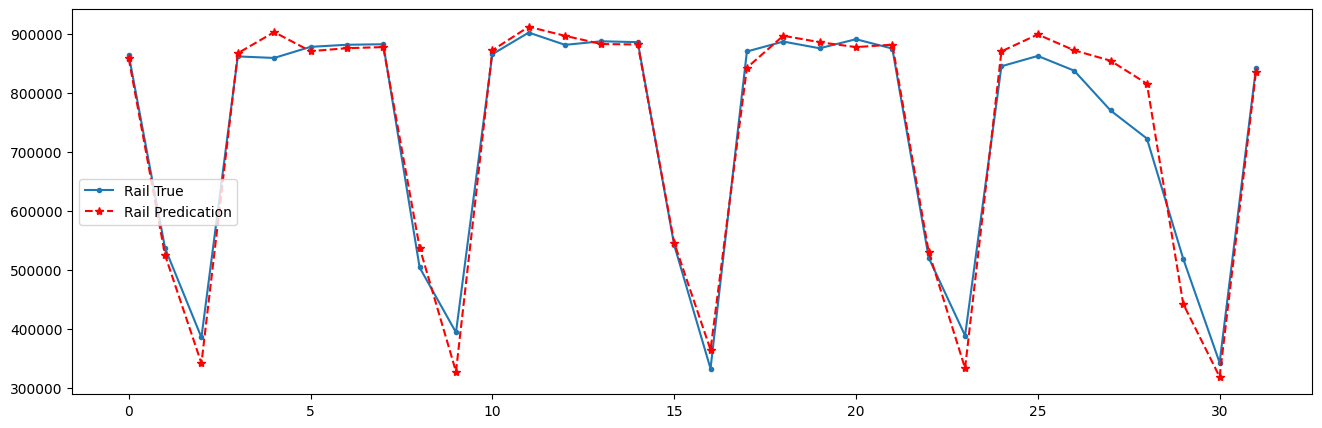

In [102]:
fig, ax = plt.subplots(figsize=(16, 5))
df["rail_true"].plot(label="Rail True", marker=".", ax=ax)
df["rail_pred"].plot(label="Rail Predication", linestyle="--", marker="*", color='r', ax=ax)
plt.legend(loc="center left")
plt.show()

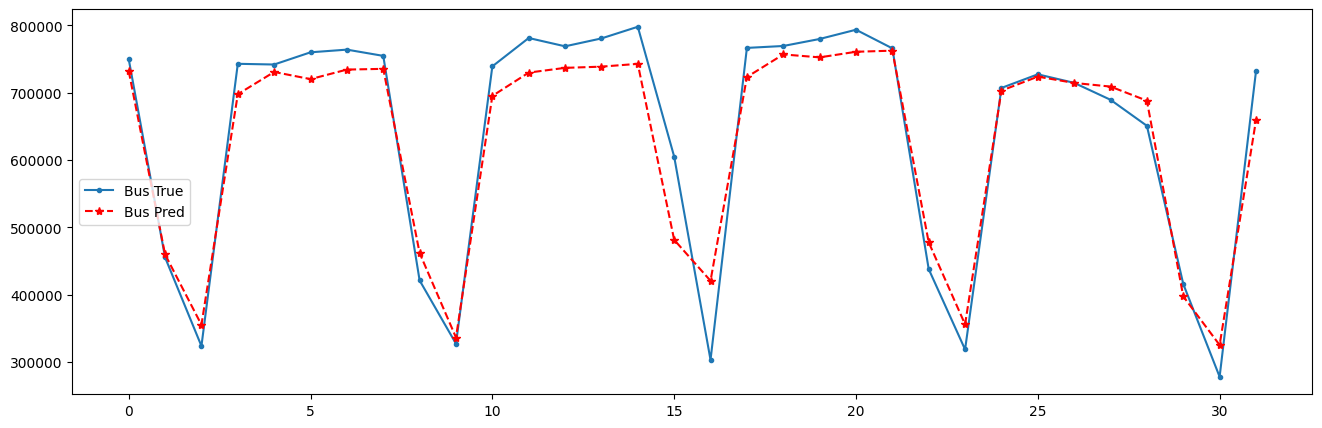

In [99]:
fig, ax = plt.subplots(figsize=(16, 5))
df["bus_true"].plot(label="Bus True", marker=".", ax=ax)
df["bus_pred"].plot(label="Bus Pred", linestyle="--",marker="*", color='r', ax=ax)
plt.legend(loc="center left")
plt.show()

In [ ]:
# ************ Ready for Production ****************